In [ ]:
import torch

print("Using device:", torch.device("cpu"))
print("PyTorch version:", torch.__version__)

Using device: cpu
PyTorch version: 2.11.0+cpu


In [ ]:
!pip install huggingface
!pip install huggingface_hub
import huggingface
import huggingface_hub
from huggingface_hub import hf_hub_download, hf_api, snapshot_download
from google import colab
from google.colab import userdata
import zipfile


# hf_hub_download(
#     repo_id="SamuelWu318/ts-satfire-processed-window",
#     filename="data.zip",
#     repo_type="dataset",
#     token=userdata.get("HF_TOKEN"),
#     local_dir="/content/data_zip"
# )

# with zipfile.ZipFile('/content/data_zip/data.zip', 'r') as data_zip:
#   data_zip.extractall('/content/data')

repo_id = "SamuelWu318/ts-satfire-processed"  # Replace with the HF repository ID
folder_to_download = "train/*"  # The folder path + wild card
local_dir = "./content/data"  # Where you want to save it locally

# Download only the specified folder
snapshot_download(
    repo_id=repo_id,
    repo_type="dataset",
    allow_patterns=folder_to_download,
    local_dir=local_dir,
    token=userdata.get("HF_TOKEN")
)

print("Download succesful")


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 84 files:   0%|          | 0/84 [00:00<?, ?it/s]

Download succesful


In [ ]:
import numpy as np
import os

# test_arr = np.load('/content/data/train/p20702159.npz')
# print(test_arr.files)
# print(test_arr['data_000'].shape)
# print(test_arr['num_windows'])

test_arr = np.load('./content/data/train/p20777152.npz')
print(test_arr.files)
print(test_arr['data'].shape)


['data', 'labels']
(3, 27, 10, 256, 256)


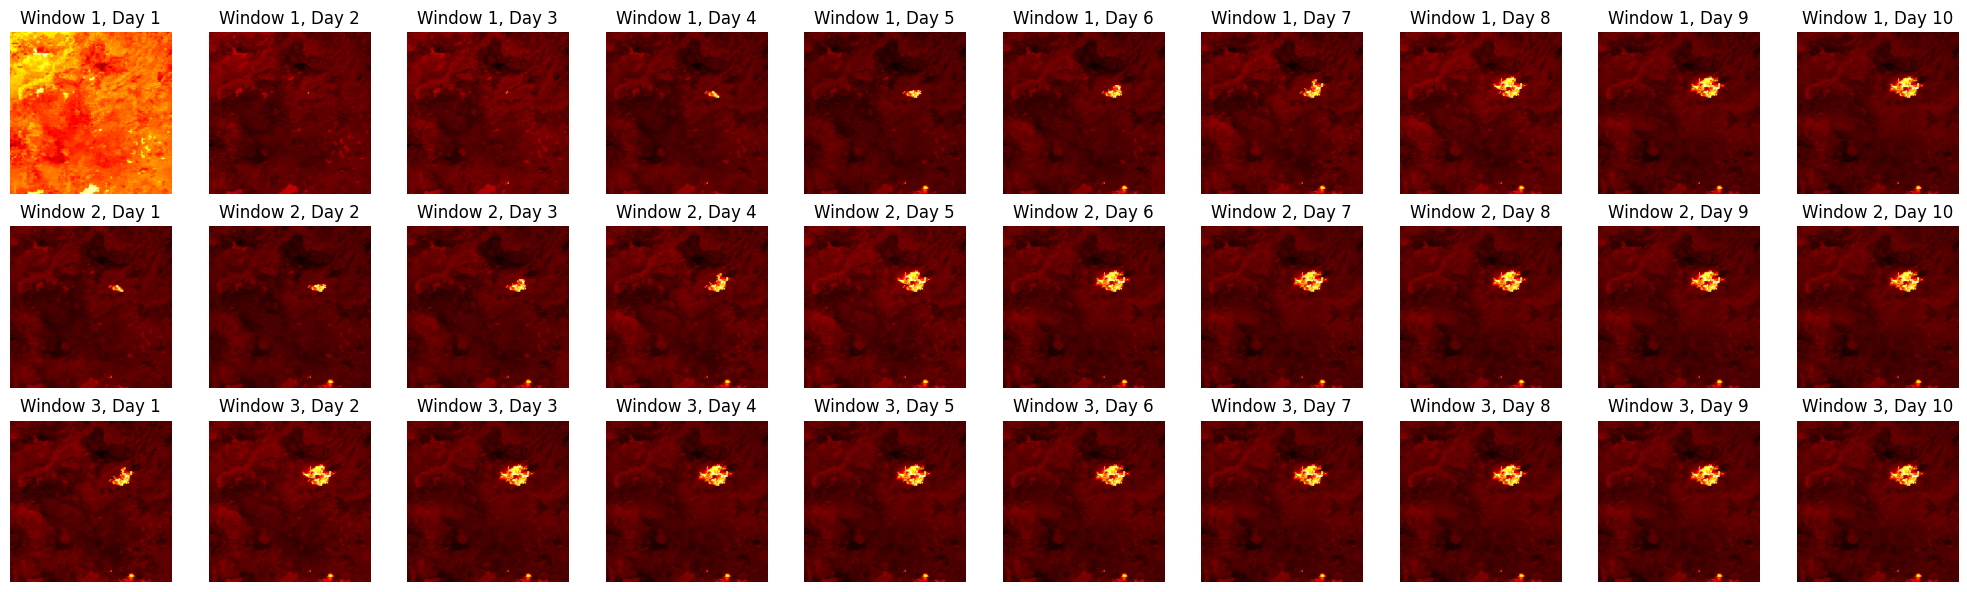

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

data_array = test_arr['data']

# Get the number of time windows
num_time_windows = data_array.shape[0]

# Assuming the 7th channel (index 6) contains the 10 active fire images
# And the 3rd dimension is the number of days (10)
num_images_per_window = data_array.shape[2] # Should be 10

# Create a figure and a grid of subplots
fig, axes = plt.subplots(num_time_windows, num_images_per_window, figsize=(2 * num_images_per_window, 2 * num_time_windows))

# Flatten axes array for easy iteration if it's not 2D (e.g., if num_time_windows or num_images_per_window is 1)
if num_time_windows == 1 and num_images_per_window == 1:
    axes = np.array([[axes]])
elif num_time_windows == 1:
    axes = axes[np.newaxis, :]
elif num_images_per_window == 1:
    axes = axes[:, np.newaxis]


for i in range(num_time_windows):
    for j in range(num_images_per_window):
        # Extract the image for the current time window (i) and day (j) from channel 6 ('I4 Night')
        image_to_plot = data_array[i, 6, j, :, :]
        ax = axes[i, j]
        ax.imshow(image_to_plot, cmap='hot', origin='lower') # Use 'hot' cmap for fire images, origin 'lower' to match typical image coords
        ax.set_title(f'Window {i+1}, Day {j+1}')
        ax.axis('off') # Hide axes for cleaner image display

plt.tight_layout()
plt.show()

IndexError: index 10 is out of bounds for axis 2 with size 10

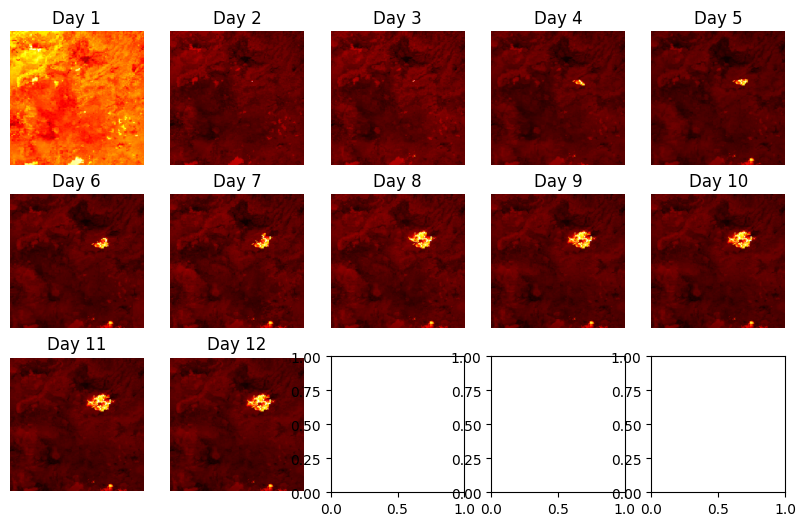

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

data_array = test_arr['data']

num_time_windows = data_array.shape[0] # 6 time windows
num_new_days_per_window = 3 # Each window introduces 3 new unique days


unique_images = [data_array[0, 6, :, :, :]]
for wi in range(1, num_time_windows):
  unique_images.append(data_array[wi, 6, 8:, :, :])

unique_arr = np.concatenate(unique_images, axis=0)

# Total number of unique images to display
total_unique_images = unique_arr.shape[0]


# Determine grid dimensions for display (e.g., 3 rows, 6 columns for 18 images)
nrows = 3
ncols = total_unique_images // nrows # 18 // 3 = 6

fig, axes = plt.subplots(nrows, ncols, figsize=(2 * ncols, 2 * nrows))

# Flatten axes array for consistent indexing, especially if nrows or ncols is 1
axes = axes.flatten()
for i in range(10):
  ax = axes[i]
  ax.imshow(data_array[0, 6, i, :, :], cmap='hot', origin='lower') # Use 'hot' cmap for fire images
  ax.set_title(f'Day {i+1}')
  ax.axis('off')

image_idx = i + 1
for i in range(1, num_time_windows):
    for j in range(8, 11):
        # Extract the image for the current time window (i) and the unique day (j=0,1,2)
        # from channel 6 ('I4 Night')
        image_to_plot = data_array[i, 6, j, :, :]

        ax = axes[image_idx]
        ax.imshow(image_to_plot, cmap='hot', origin='lower') # Use 'hot' cmap for fire images

        # Calculate the actual day number based on the window and index within the window
        actual_day_number = image_idx + 1
        ax.set_title(f'Day {actual_day_number}') # Display day numbers as 1-indexed
        ax.axis('off') # Hide axes for cleaner image display
        image_idx += 1

plt.tight_layout()
plt.show()

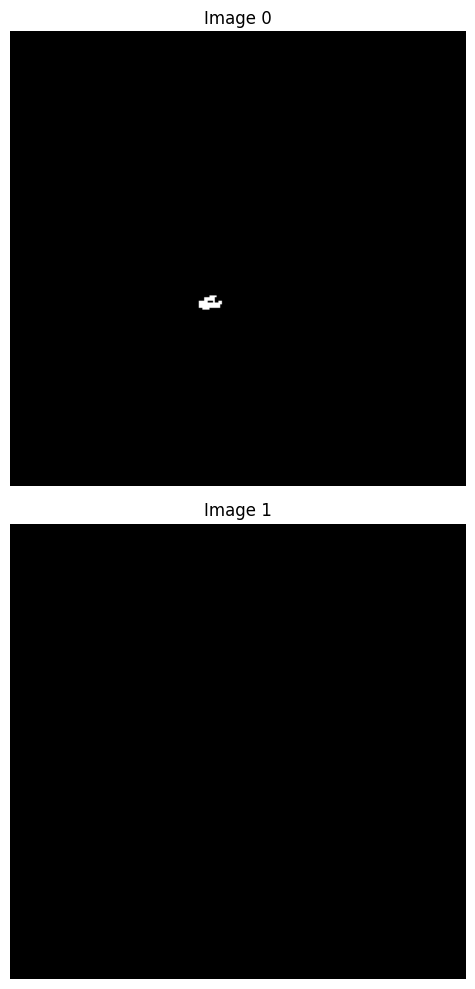

In [ ]:
import matplotlib.pyplot as plt


num_labels = test_arr['labels'].shape[0]
nrows = 2
ncols = (num_labels + nrows - 1) // nrows
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(5 * ncols, 5 * nrows))

# Ensure axes is always a 2D array for consistent indexing
if nrows == 1 and ncols == 1:
    axes = np.array([[axes]])
elif nrows == 1 or ncols == 1:
    axes = axes.reshape(nrows, ncols)

for i in range(test_arr['labels'].shape[0]):
  row_idx = i // ncols
  col_idx = i % ncols
  ax = axes[row_idx, col_idx]

  image_to_plot = test_arr['labels'][i]
  ax.imshow(image_to_plot, cmap='gray') # Assuming grayscale images
  ax.set_title(f'Image {i}') # Use the key as the title
  ax.axis('off') # Hide axes for cleaner image display

# Hide any unused subplots
for i in range(num_labels, nrows * ncols):
    row_idx = i // ncols
    col_idx = i % ncols
    fig.delaxes(axes[row_idx, col_idx])

plt.tight_layout()
plt.show()


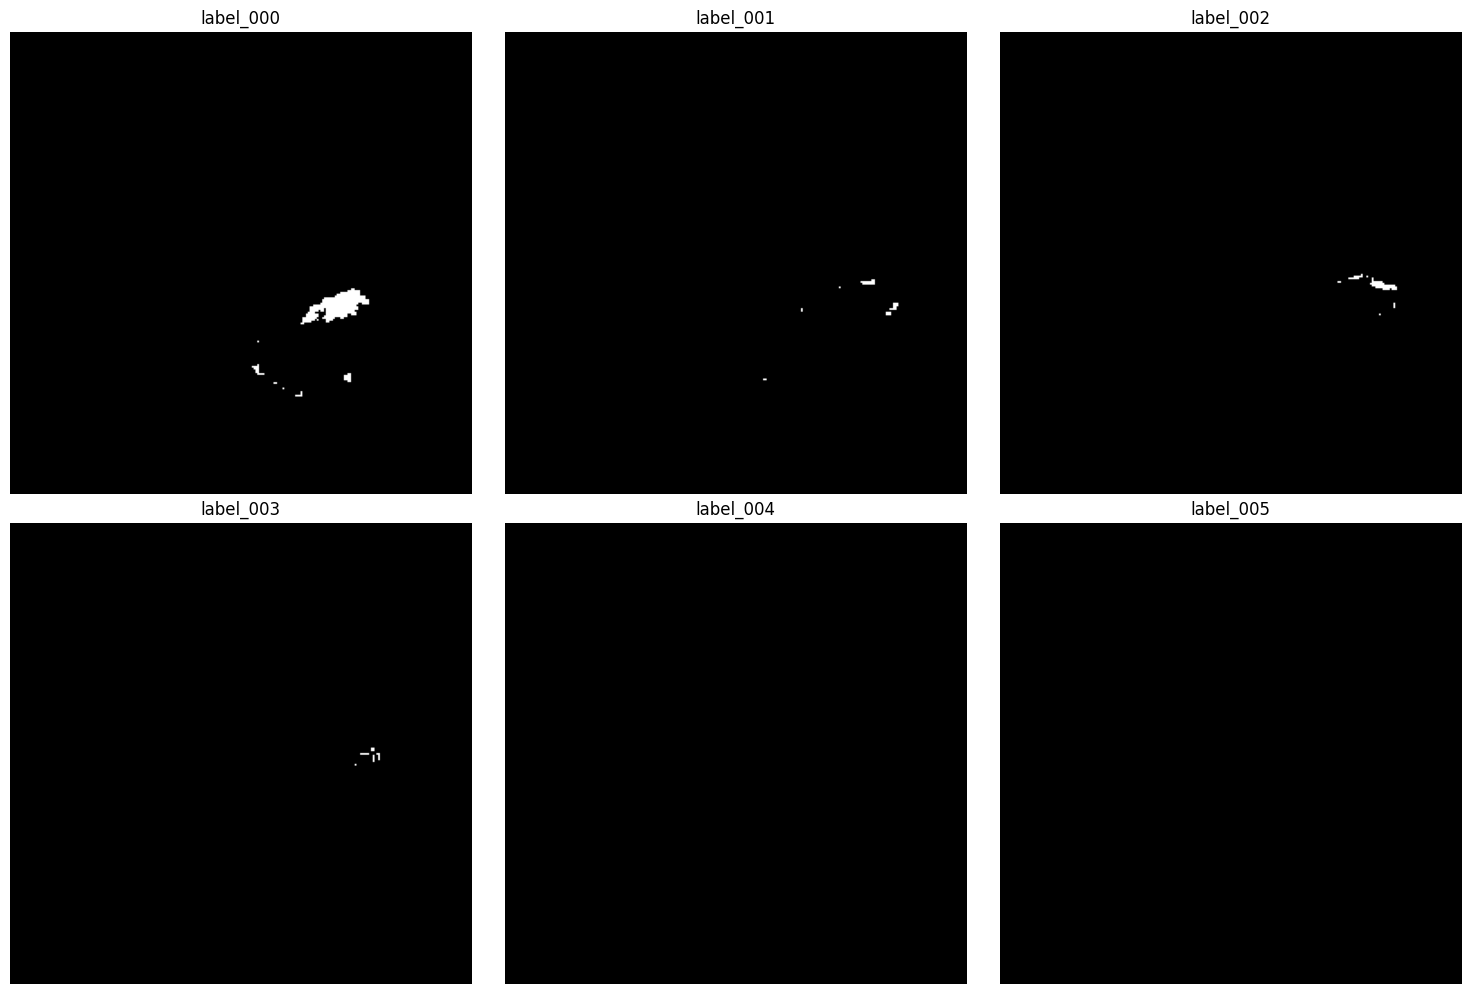

In [ ]:
import matplotlib.pyplot as plt
import numpy as np # Import numpy for potential array reshaping

# Get all 'label_XXX' keys from test_arr
label_keys = [f for f in test_arr.files if f.startswith('label_')]

num_labels = len(label_keys)
nrows = 2
ncols = (num_labels + nrows - 1) // nrows # Calculate columns needed for 2 rows

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(5 * ncols, 5 * nrows))

# Ensure axes is always a 2D array for consistent indexing
if nrows == 1 and ncols == 1:
    axes = np.array([[axes]])
elif nrows == 1 or ncols == 1:
    axes = axes.reshape(nrows, ncols)

for i, key in enumerate(label_keys):
    row_idx = i // ncols
    col_idx = i % ncols

    ax = axes[row_idx, col_idx]

    image_to_plot = test_arr[key]
    ax.imshow(image_to_plot, cmap='gray') # Assuming grayscale images
    ax.set_title(f'{key}') # Use the key as the title
    ax.axis('off') # Hide axes for cleaner image display

# Hide any unused subplots
for i in range(num_labels, nrows * ncols):
    row_idx = i // ncols
    col_idx = i % ncols
    fig.delaxes(axes[row_idx, col_idx])

plt.tight_layout()
plt.show()

In [ ]:
CHANNELS = ["I1", "I2", "I3", "I4", "I5", "M11", "I4 Night", "I5 Night", "NDVI", "EVI"]
BURN_AREA_MASK = "ba_mask"

def get_channel(channel_name: str):
  """
  Collects numpy array slices for a given channel across all data files.

  Args:
    channel_name (str): The name of the channel to extract (e.g., "I1", "ba_mask").

  Returns:
    list[np.ndarray]: A list of numpy array slices, each corresponding to the requested channel
                      and the last three time steps (e.g., shape (3, H, W)).
  """
  is_ba_mask = (channel_name == BURN_AREA_MASK)

  if not is_ba_mask and channel_name not in CHANNELS:
    raise ValueError(f"Channel '{channel_name}' not found in {CHANNELS} or is not '{BURN_AREA_MASK}'")

  channel_idx = None
  if not is_ba_mask:
      channel_idx = CHANNELS.index(channel_name)

  collected_slices = []

  for folder in ['train']:
    for file_name in os.listdir(f'/content/data/{folder}'):
      if not file_name.endswith('.npz'):
          continue
      npz_file_path = os.path.join(f'/content/data/{folder}', file_name)
      print(npz_file_path)
      with np.load(npz_file_path, mmap_mode='r') as npz_data:
        num_windows = npz_data['num_windows']
        base_key = "label" if is_ba_mask else "data"
        # Explicitly copy the slice to ensure data persists after mmap is closed
        collected_slices.append(npz_data[f'{base_key}_000'][channel_idx, :7, :, :].copy())

        for i in range(num_windows):
          base_key = "label" if is_ba_mask else "data"
          arr_key = f'{base_key}_{i:03d}'

          if arr_key in npz_data:
              arr = npz_data[arr_key]

              if is_ba_mask:
                  # Explicitly copy the slice
                  collected_slices.append(arr[-3:, :, :].copy())
              else:
                  # Explicitly copy the slice
                  collected_slices.append(arr[channel_idx, :, :, :][-3:, :, :].copy())
          else:
              print(f"Warning: Key '{arr_key}' not found in {file_name} from {npz_file_path}")

  return np.concatenate(collected_slices, axis=0)

In [ ]:
# Get slices for 'I1' channel
i1_slices = get_channel('I1')


print(f"Number of collected 'I1' slices: {len(i1_slices)}")
print(f"Shape of the combined 'I1' array: {i1_slices.shape}")

/content/data/train/p24461320.npz
/content/data/train/p24332622.npz
/content/data/train/p24333033.npz
/content/data/train/p23860939.npz
/content/data/train/p24332880.npz
/content/data/train/p21890003.npz
/content/data/train/p21890024.npz
/content/data/train/p24333039.npz
/content/data/train/p22938749.npz
/content/data/train/p21998264.npz
/content/data/train/p21158940.npz
/content/data/train/p21997828.npz
/content/data/train/p23300669.npz
/content/data/train/p20777134.npz
/content/data/train/p24462819.npz
/content/data/train/p24332647.npz
/content/data/train/p20777152.npz
/content/data/train/p24462488.npz
/content/data/train/p24333000.npz
/content/data/train/p24461899.npz
/content/data/train/p21804985.npz
/content/data/train/p21998230.npz
/content/data/train/p21804582.npz
/content/data/train/p20778153.npz
/content/data/train/p20899892.npz
/content/data/train/p20899967.npz
/content/data/train/p21751309.npz
/content/data/train/p21038333.npz
/content/data/train/p24332746.npz
/content/data/

AttributeError: 'list' object has no attribute 'shape'

In [ ]:
print(type(i1_slices))
for arr in i1_slices:
  print(arr.shape)

<class 'list'>
(7, 256, 256)
(3, 256, 256)
(3, 256, 256)
(7, 256, 256)
(3, 256, 256)
(3, 256, 256)
(3, 256, 256)
(3, 256, 256)
(7, 256, 256)
(3, 256, 256)
(3, 256, 256)
(3, 256, 256)
(3, 256, 256)
(7, 256, 256)
(3, 256, 256)
(3, 256, 256)
(3, 256, 256)
(3, 256, 256)
(7, 256, 256)
(3, 256, 256)
(7, 256, 256)
(3, 256, 256)
(3, 256, 256)
(3, 256, 256)
(3, 256, 256)
(3, 256, 256)
(3, 256, 256)
(3, 256, 256)
(7, 256, 256)
(3, 256, 256)
(3, 256, 256)
(7, 256, 256)
(3, 256, 256)
(3, 256, 256)
(3, 256, 256)
(3, 256, 256)
(3, 256, 256)
(3, 256, 256)
(3, 256, 256)
(7, 256, 256)
(3, 256, 256)
(3, 256, 256)
(3, 256, 256)
(3, 256, 256)
(3, 256, 256)
(7, 256, 256)
(3, 256, 256)
(3, 256, 256)
(3, 256, 256)
(7, 256, 256)
(3, 256, 256)
(3, 256, 256)
(3, 256, 256)
(7, 256, 256)
(3, 256, 256)
(3, 256, 256)
(3, 256, 256)
(3, 256, 256)
(3, 256, 256)
(7, 256, 256)
(3, 256, 256)
(3, 256, 256)
(7, 256, 256)
(3, 256, 256)
(3, 256, 256)
(3, 256, 256)
(3, 256, 256)
(3, 256, 256)
(3, 256, 256)
(3, 256, 256)
(3, 2

In [ ]:
del i1_slices
import gc
gc.collect()

639